# Practica 1.1. Manipuación de datos

## Objetivo

En esta práctica, aprenderás a aplicar técnicas de análisis de datos utilizando Pandas para explorar un dataset relacionado con la salud mental. El objetivo es que pongas en práctica tus habilidades de manipulación, limpieza y análisis de datos para obtener conclusiones interesantes.


# Instalación


pip install --upgrade pip


---

## Paso 1: Carga del Dataset

Primero, vas a cargar el archivo CSV que contiene la información sobre diferentes factores que influyen en la salud mental. Utiliza la biblioteca Pandas para leer el archivo y observa las primeras filas del dataset. Esto te ayudará a familiarizarte con la información que vas a analizar.

---

### Importamos las librerias para la carga, análisis y visualización de los datos

In [30]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [31]:
# ------ Carga del Dataset---------

# Carpeta de datos
carpeta = 'dataset/'

# Nombre del archivo
archivo = 'mental_health.csv'

# Usando la librería de Pandas se carga el archivo
df_mental_health = pd.read_csv(carpeta+archivo)

# Se muestran las cinco primeras filas del dataframe
df_mental_health.head()

,Age,Gender,Education_Level,Employment_Status,Sleep_Hours,Physical_Activity_Hrs,Social_Support_Score,Anxiety_Score,Depression_Score,Stress_Level,...,Chronic_Illnesses,Medication_Use,Therapy,Meditation,Substance_Use,Financial_Stress,Work_Stress,Self_Esteem_Score,Life_Satisfaction_Score,Loneliness_Score
0,56,Male,Bachelor's,Unemployed,6.0,0.4,3,4,2,9,...,0,NaN,0,1,NaN,4,3,7,5,1
1,69,Female,Bachelor's,Retired,8.8,2.8,6,18,7,6,...,0,NaN,1,0,NaN,1,4,7,4,6
2,46,Female,Master's,Employed,5.3,1.6,5,5,13,8,...,0,NaN,0,1,NaN,8,7,8,1,1
3,32,Female,High School,Unemployed,8.8,0.5,4,6,3,4,...,1,NaN,0,0,NaN,7,4,8,4,4
4,60,Female,Bachelor's,Retired,7.2,0.7,2,7,15,3,...,0,NaN,1,1,Frequent,8,9,5,7,7


In [32]:
# Mostrar información del dataframe
df_mental_health.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1200 entries, 0 to 1199
Data columns (total 21 columns):
 #   Column                         Non-Null Count  Dtype  
---  ------                         --------------  -----  
 0   Age                            1200 non-null   int64  
 1   Gender                         1200 non-null   object 
 2   Education_Level                1200 non-null   object 
 3   Employment_Status              1200 non-null   object 
 4   Sleep_Hours                    1200 non-null   float64
 5   Physical_Activity_Hrs          1200 non-null   float64
 6   Social_Support_Score           1200 non-null   int64  
 7   Anxiety_Score                  1200 non-null   int64  
 8   Depression_Score               1200 non-null   int64  
 9   Stress_Level                   1200 non-null   int64  
 10  Family_History_Mental_Illness  1200 non-null   int64  
 11  Chronic_Illnesses              1200 non-null   int64  
 12  Medication_Use                 453 non-null    o

### Preguntas:

1. ¿Cuántos registros y columnas tiene el dataset?
   
   El dataset contiene:

   * 1200 registros, 
  
   * 21 columnas, 
   
   * el dataframe usa un total de memoria de 197 KB.

2. ¿Qué tipo de datos predominan?
   Dentro del dataset existen tres tipos de datos:

      a. **float64**: 2 columnas

      b. **object**: 5 columnas

      c. **int64**: 14 columnas

   Las columnas de tipo **int64** contienen el mayor número de columnas.


---

## Paso 2: Exploración Inicial

Ahora que ya tienes los datos cargados, es momento de explorar un poco más. Consulta información general como el tipo de datos en cada columna, cuántos datos no nulos hay, y revisa las primeras filas. También obtén estadísticas básicas como la media y el rango de los datos. Esto te ayudará a detectar si algo llama la atención o si hay datos fuera de lo normal.

---

### Tipos de datos por columna

In [33]:
# Tipo de datos de cada columna
df_mental_health.dtypes

Age                                int64
Gender                            object
Education_Level                   object
Employment_Status                 object
Sleep_Hours                      float64
Physical_Activity_Hrs            float64
Social_Support_Score               int64
Anxiety_Score                      int64
Depression_Score                   int64
Stress_Level                       int64
Family_History_Mental_Illness      int64
Chronic_Illnesses                  int64
Medication_Use                    object
Therapy                            int64
Meditation                         int64
Substance_Use                     object
Financial_Stress                   int64
Work_Stress                        int64
Self_Esteem_Score                  int64
Life_Satisfaction_Score            int64
Loneliness_Score                   int64
dtype: object

Los tipos de dato de columna se pueden organizar de la siguiente manera:

a. 2 columnas de tipo float64:

* Sleep_Hours
    
* Physical_Activity_Hrs

b. 5 columnas de tipo objects:

* Gender
    
* Education_Level
  
* Employment_Status
  
* Medication_Use 
  
* Substance_Use

c. 14 columnas de tipo int64: Age, Social_Support_Score, Anxiety_Score, Depression_Score, Stress_Level, Stress_Level, Chronic_Illnesses, Therapy, Meditation, Financial_Stress, Work_Stress, Self_Esteem_Score, Life_Satisfaction_Score, Loneliness_Score.

### Valores nulos

In [34]:
# Valores nulos de cada columna
df_mental_health.isnull().sum()

Age                                0
Gender                             0
Education_Level                    0
Employment_Status                  0
Sleep_Hours                        0
Physical_Activity_Hrs              0
Social_Support_Score               0
Anxiety_Score                      0
Depression_Score                   0
Stress_Level                       0
Family_History_Mental_Illness      0
Chronic_Illnesses                  0
Medication_Use                   747
Therapy                            0
Meditation                         0
Substance_Use                    834
Financial_Stress                   0
Work_Stress                        0
Self_Esteem_Score                  0
Life_Satisfaction_Score            0
Loneliness_Score                   0
dtype: int64

In [35]:
# Porcentaje de valores nulos por cada columna
porcentaje_nulos = df_mental_health.isnull().sum() / len(df_mental_health) * 100
porcentaje_nulos[porcentaje_nulos > 0].sort_values(ascending=False)

Substance_Use     69.50
Medication_Use    62.25
dtype: float64

Del dataframe solo se tienen dos columnas de tipo objeto con valores nulos:

* Medication_Use con 747 valores nulos de 1200 valores totales lo que representa el 62.25 % de datos nulos

* Substance_Use con 834 vvalores nulos de 1200 valores totales lo que representa el 69.50 % de datos nulos

In [36]:
# Mostrar las primeras filas del dataframe
df_mental_health.head()

,Age,Gender,Education_Level,Employment_Status,Sleep_Hours,Physical_Activity_Hrs,Social_Support_Score,Anxiety_Score,Depression_Score,Stress_Level,...,Chronic_Illnesses,Medication_Use,Therapy,Meditation,Substance_Use,Financial_Stress,Work_Stress,Self_Esteem_Score,Life_Satisfaction_Score,Loneliness_Score
0,56,Male,Bachelor's,Unemployed,6.0,0.4,3,4,2,9,...,0,NaN,0,1,NaN,4,3,7,5,1
1,69,Female,Bachelor's,Retired,8.8,2.8,6,18,7,6,...,0,NaN,1,0,NaN,1,4,7,4,6
2,46,Female,Master's,Employed,5.3,1.6,5,5,13,8,...,0,NaN,0,1,NaN,8,7,8,1,1
3,32,Female,High School,Unemployed,8.8,0.5,4,6,3,4,...,1,NaN,0,0,NaN,7,4,8,4,4
4,60,Female,Bachelor's,Retired,7.2,0.7,2,7,15,3,...,0,NaN,1,1,Frequent,8,9,5,7,7


La salida anterior nos muestra las primeras cinco filas del dataframe, se puede observar algunas columnas que tienen el tipo de dato *object* con frases de texto las cuales se deben cambiar al tipo categórico, además, se pueden ven columnas del tipo numérico que continen niveles o puntuaciones que se pueden considerar como categóricas, tal es el caso de: Chronic_Illnesses, Medication_Use, Therapy, Meditation. Comprobemos a continuación el rango de valores para determinar si actualmente las columnas contienen valores o tipos erroneos.

### Estasdísticas básicas por tipo de variable

In [37]:
# Mostrar estadísticas descriptivas de las variables de tipo objeto
df_mental_health.describe(include=['object'])

,Gender,Education_Level,Employment_Status,Medication_Use,Substance_Use
count,1200,1200,1200,453,366
unique,4,5,4,2,2
top,Female,PhD,Employed,Regular,Occasional
freq,569,262,320,238,242


Las variables de tipo *object* son variables categóricas que contienen en su mayoria textos que se pueden cambiar por un rango de números enteros, como se puede observar la frecuencia de valores únicos no supera a 5, mientras que las de menor valor al menos contienen dos tipos diferentes de variables.

In [38]:
# Mostrar estadísticas descriptivas de las variables numéricas
df_mental_health.describe(include=[np.number])

,Age,Sleep_Hours,Physical_Activity_Hrs,Social_Support_Score,Anxiety_Score,Depression_Score,Stress_Level,Family_History_Mental_Illness,Chronic_Illnesses,Therapy,Meditation,Financial_Stress,Work_Stress,Self_Esteem_Score,Life_Satisfaction_Score,Loneliness_Score
count,1200.000000,1200.00000,1200.000000,1200.000000,1200.000000,1200.000000,1200.000000,1200.000000,1200.00000,1200.000000,1200.000000,1200.000000,1200.000000,1200.000000,1200.00000,1200.000000
mean,46.317500,6.46900,2.005750,5.055000,10.470000,10.674167,5.000833,0.318333,0.26750,0.210000,0.399167,4.992500,4.889167,5.062500,5.12000,4.959167
std,16.451157,1.52955,2.037818,2.652893,5.911138,5.632889,2.538281,0.466024,0.44284,0.407478,0.489931,2.590953,2.547016,2.531587,2.56991,2.566383
min,18.000000,2.00000,0.000000,1.000000,1.000000,1.000000,1.000000,0.000000,0.00000,0.000000,0.000000,1.000000,1.000000,1.000000,1.00000,1.000000
25%,33.000000,5.40000,0.600000,3.000000,5.000000,6.000000,3.000000,0.000000,0.00000,0.000000,0.000000,3.000000,3.000000,3.000000,3.00000,3.000000
50%,46.000000,6.40000,1.400000,5.000000,10.500000,11.000000,5.000000,0.000000,0.00000,0.000000,0.000000,5.000000,5.000000,5.000000,5.00000,5.000000
75%,61.000000,7.50000,2.700000,7.000000,16.000000,15.000000,7.000000,1.000000,1.00000,0.000000,1.000000,7.000000,7.000000,7.000000,7.00000,7.000000
max,74.000000,12.40000,15.100000,9.000000,20.000000,20.000000,9.000000,1.000000,1.00000,1.000000,1.000000,9.000000,9.000000,9.000000,9.00000,9.000000


Los ragos de algunas columnas llaman la atención por ejemplo, la edad minima registra es de 18 años, y la máxima 74 años, dentro de las horas de sueño el valor mínimo es de dos horas lo cual llama la atención por el rango de edades y la máxima 12.4 hrs, esto puede ser un poco confuso al trasladar la hora y fracción a horas y minutos, así que recomendaría aclarar si la parte fraccionaria representa 0.1 representa 6 min.

Como se puede observar en la salida anterior existen variables numéricas como: Family_History_Mental_Illness, Chronic_Illnesses, Therapy y Meditation que solo contiene como valor mínimo 0 y como máximo 1 mostrando así un comportamiento más categórico que numérico.

### Preguntas:

1. ¿Existen columnas que podrían ser categóricas pero aparecen como tipo `object`?
   Las cinco columnas que aparecen como tipo *object* son categóricas a demás de Family_History_Mental_Illness, Chronic_Illnesses, Therapy y Meditation que solo manjean valores binarios de 0 y 1 deben ser consideradas como variables categóricas.

2. ¿Hay valores que parecen inconsistentes o fuera de rango? No, al parecer dentro de los valores las variables contienen rangos de acuerdo a su objetivo, sin embargo existen variables que muestran interés de análisis al mostrar valores tan bajos como las horas de sueño, actividad física así como nivele de estrés o depresión para determinar si existe un correlación entre estas.

---
## Paso 3: Limpieza de Datos

Es hora de "limpiar" los datos. Revisa si hay valores nulos o datos duplicados. Decide qué hacer con ellos: ¿los eliminarás, los reemplazarás o aplicarás otra estrategia? También asegúrate de que los tipos de datos de cada columna son correctos y convierte aquellos que no estén en el formato adecuado.

---

###  Tratamiento de datos nulos

In [39]:
# Valores nulos de cada columna
df_mental_health.isnull().sum()

Age                                0
Gender                             0
Education_Level                    0
Employment_Status                  0
Sleep_Hours                        0
Physical_Activity_Hrs              0
Social_Support_Score               0
Anxiety_Score                      0
Depression_Score                   0
Stress_Level                       0
Family_History_Mental_Illness      0
Chronic_Illnesses                  0
Medication_Use                   747
Therapy                            0
Meditation                         0
Substance_Use                    834
Financial_Stress                   0
Work_Stress                        0
Self_Esteem_Score                  0
Life_Satisfaction_Score            0
Loneliness_Score                   0
dtype: int64

Como se mostró en el apartado anterior, solo se tienen dos columnas de tipo objeto con valores nulos:

* Medication_Use con 747 valores nulos de 1200 valores totales lo que representa el 62.25 % de datos nulos

* Substance_Use con 834 vvalores nulos de 1200 valores totales lo que representa el 69.50 % de datos nulos

Los porcentajes de valores nulos en este caso son muy altos, eliminarlos genera el 69.50% de pérdida de los datos, reaalizar alguna imputación como rellenar por frecuencia o vecinos se considera muy peligroso ya que el análisis se dirije a temas de salud. En este caso se decide rellenar la columna con una categoría más: 'No reportado', la cual no afectará la estructura, los valores o disminuir la cantidad de datos disponibles.

In [40]:
# Rellenar valores nulos con la frase: 'Not Reported'
df_mental_health.fillna('Not Reported', inplace=True)
df_mental_health.head()

,Age,Gender,Education_Level,Employment_Status,Sleep_Hours,Physical_Activity_Hrs,Social_Support_Score,Anxiety_Score,Depression_Score,Stress_Level,...,Chronic_Illnesses,Medication_Use,Therapy,Meditation,Substance_Use,Financial_Stress,Work_Stress,Self_Esteem_Score,Life_Satisfaction_Score,Loneliness_Score
0,56,Male,Bachelor's,Unemployed,6.0,0.4,3,4,2,9,...,0,Not Reported,0,1,Not Reported,4,3,7,5,1
1,69,Female,Bachelor's,Retired,8.8,2.8,6,18,7,6,...,0,Not Reported,1,0,Not Reported,1,4,7,4,6
2,46,Female,Master's,Employed,5.3,1.6,5,5,13,8,...,0,Not Reported,0,1,Not Reported,8,7,8,1,1
3,32,Female,High School,Unemployed,8.8,0.5,4,6,3,4,...,1,Not Reported,0,0,Not Reported,7,4,8,4,4
4,60,Female,Bachelor's,Retired,7.2,0.7,2,7,15,3,...,0,Not Reported,1,1,Frequent,8,9,5,7,7


### Cambiar tipos de datos

In [41]:
# Columnas con el tipo de dato 'object'
columnas_objeto = df_mental_health.select_dtypes(include=['object']).columns
# Convertir columnas de tipo 'object' a 'category'
for col in columnas_objeto:
    df_mental_health[col] = df_mental_health[col].astype('category')
# Verificar el cambio de tipo de dato
df_mental_health.dtypes


Age                                 int64
Gender                           category
Education_Level                  category
Employment_Status                category
Sleep_Hours                       float64
Physical_Activity_Hrs             float64
Social_Support_Score                int64
Anxiety_Score                       int64
Depression_Score                    int64
Stress_Level                        int64
Family_History_Mental_Illness       int64
Chronic_Illnesses                   int64
Medication_Use                   category
Therapy                             int64
Meditation                          int64
Substance_Use                    category
Financial_Stress                    int64
Work_Stress                         int64
Self_Esteem_Score                   int64
Life_Satisfaction_Score             int64
Loneliness_Score                    int64
dtype: object

In [42]:
# Cambiar las columnas Family_History_Mental_Illness, Chronic_Illnesses, Therapy y Meditation a 'category'
df_mental_health['Family_History_Mental_Illness'] = df_mental_health['Family_History_Mental_Illness'].astype('category')
df_mental_health['Chronic_Illnesses'] = df_mental_health['Chronic_Illnesses'].astype('category')
df_mental_health['Therapy'] = df_mental_health['Therapy'].astype('category')
df_mental_health['Meditation'] = df_mental_health['Meditation'].astype('category')
# Verificar el cambio de tipo de dato
df_mental_health.dtypes

Age                                 int64
Gender                           category
Education_Level                  category
Employment_Status                category
Sleep_Hours                       float64
Physical_Activity_Hrs             float64
Social_Support_Score                int64
Anxiety_Score                       int64
Depression_Score                    int64
Stress_Level                        int64
Family_History_Mental_Illness    category
Chronic_Illnesses                category
Medication_Use                   category
Therapy                          category
Meditation                       category
Substance_Use                    category
Financial_Stress                    int64
Work_Stress                         int64
Self_Esteem_Score                   int64
Life_Satisfaction_Score             int64
Loneliness_Score                    int64
dtype: object

### Preguntas:

1. ¿Qué porcentaje del dataset contiene valores nulos?
   Los porcentajes de valores nulos son:

   * Medication_Use con 747 valores nulos de 1200 valores totales lo que representa el 62.25 % de datos nulos

   * Substance_Use con 834 vvalores nulos de 1200 valores totales lo que representa el 69.50 % de datos nulos
   
2. ¿Qué estrategia decidiste aplicar para tratar los valores nulos y por qué?
   Los porcentajes de valores nulos en este caso son muy altos, eliminarlos genera el 69.50% de pérdida de los datos, realizar alguna imputación como rellenar por frecuencia o vecinos se considera muy peligroso ya que el análisis se dirije a temas de salud. En este caso se decide rellenar la columna con una categoría más: 'No reportado', la cual no afectará la estructura, los valores o disminuir la cantidad de datos disponibles.

---
## Paso 4: Análisis Estadístico

En este paso, vas a calcular algunas estadísticas básicas para tres columnas importantes: `Anxiety_Score`, `Depression_Score` y `Stress_Level`. Queremos saber cuál es la media, la mediana y la desviación estándar de estos valores. Esto te permitirá tener una idea general sobre cómo están distribuidos estos puntajes.

---

In [47]:
# Calcular la media, mediana y moda de la columna Anxiety_Score
media = df_mental_health['Anxiety_Score'].mean()
mediana = df_mental_health['Anxiety_Score'].median()
moda = df_mental_health['Anxiety_Score'].mode()[0]
desviacion_estandar = df_mental_health['Anxiety_Score'].std()
# Mostrar los resultados
print(f'Media: {media}')
print(f'Mediana: {mediana}')
print(f'Moda: {moda}')
print(f'Desviación Estándar: {desviacion_estandar}')

Media: 10.47
Mediana: 10.5
Moda: 1
Desviación Estándar: 5.911137901685593


**Anxiety_Score**

La media y mediana son valores muy cercano, lo cual sugiere que la distribución es aproximadamente simétrica, el valor de la desv. estad. muestra bastante dispersión en los niveles de ansiedad, esto sugiere que existen valores de personas significativamente altos o muy bajos que aumentan el rango de valores.

In [48]:
# Calcular la media, mediana y moda de la columna Depression_Score
media = df_mental_health['Depression_Score'].mean()
mediana = df_mental_health['Depression_Score'].median()
moda = df_mental_health['Depression_Score'].mode()[0]
desviacion_estandar = df_mental_health['Depression_Score'].std()
# Mostrar los resultados
print(f'Media: {media}')
print(f'Mediana: {mediana}')
print(f'Moda: {moda}')
print(f'Desviación Estándar: {desviacion_estandar}')

Media: 10.674166666666666
Mediana: 11.0
Moda: 12
Desviación Estándar: 5.632889179273564


**Depression_Score**

Los valores de la media y mediana son valores cercanos indicando una distribución muy simétrica, por otro lado la desv. estd. sugiere que hay bastante variabilidad en los niveles de depresión.

In [49]:
# Calcular la media, mediana y moda de la columna Stress_Level
media = df_mental_health['Stress_Level'].mean()
mediana = df_mental_health['Stress_Level'].median()
moda = df_mental_health['Stress_Level'].mode()[0]
desviacion_estandar = df_mental_health['Stress_Level'].std()
# Mostrar los resultados
print(f'Media: {media}')
print(f'Mediana: {mediana}')
print(f'Moda: {moda}')
print(f'Desviación Estándar: {desviacion_estandar}')


Media: 5.0008333333333335
Mediana: 5.0
Moda: 4
Desviación Estándar: 2.538280591763709


**Stress_Level**
Los valores de la media y mediana son aproximadamente iguales lo que sugiere una distribución simétrica, por el lado de la desv. estd. tienen una dispersión muy baja y estable. 


### Preguntas:

1. ¿Cuál de los tres puntajes tiene mayor variabilidad?
   
   La vaiable con mayor variabilidad es Anxiety_Score con una desv. estd. de 5.911

2. ¿Qué observas sobre la diferencia entre media y mediana en cada caso? ¿Qué te dice esto sobre la distribución?
   Al comparar las media y mediana de cada caso se observa mucha proximidad lo que sugiere que las distribuciones son aproximadamente simétricas, además de no estar sesgadas significativamente. Stress_Level es la variable que parece seguir una distribución normal mientras que Anxiety_Score y Depression_Score tienen más dispersión y variailidad.



---
## Paso 5: Filtrado de Datos

Aquí vas a enfocarte en subconjuntos específicos del dataset. Primero, identifica a las personas que tienen un puntaje alto en ansiedad (puedes elegir un valor alto, como por encima de 80). Luego, clasifica a las personas según las horas de sueño que reportan (menos de 5 horas, entre 5 y 7 horas, y más de 7 horas) y analiza cómo varía el nivel de estrés en cada grupo.

---

### Personas con puntaje alto de Ansiedad

In [50]:
# Rango de valores de la columna Anxiety_Score
rango_anxiety = df_mental_health['Anxiety_Score'].max() - df_mental_health['Anxiety_Score'].min()
print(f'Rango de Anxiety_Score: {rango_anxiety}')

Rango de Anxiety_Score: 19


In [61]:
# Elgimos el 80% del intervalo de Anxiety_Score
percentil_80 = df_mental_health['Anxiety_Score'].quantile(0.8)
print(f'Percentil 80 de Anxiety_Score: {percentil_80}')
# Filtramos los valores de Anxiety_Score que son mayores al percentil 80
anxiety_high = df_mental_health[df_mental_health['Anxiety_Score'] > percentil_80].reset_index(drop=True)
anxiety_high

Percentil 80 de Anxiety_Score: 17.0


,Age,Gender,Education_Level,Employment_Status,Sleep_Hours,Physical_Activity_Hrs,Social_Support_Score,Anxiety_Score,Depression_Score,Stress_Level,...,Medication_Use,Therapy,Meditation,Substance_Use,Financial_Stress,Work_Stress,Self_Esteem_Score,Life_Satisfaction_Score,Loneliness_Score,Clasificacion_Suenio
0,69,Female,Bachelor's,Retired,8.8,2.8,6,18,7,6,...,Not Reported,1,0,Not Reported,1,4,7,4,6,Mucho Sueño
1,28,Male,Other,Retired,5.6,6.3,9,18,20,1,...,Occasional,0,0,Occasional,9,4,3,7,5,Sueño Normal
2,29,Other,Bachelor's,Unemployed,6.0,2.6,7,18,3,8,...,Not Reported,1,0,Not Reported,5,5,6,4,3,Sueño Normal
3,39,Male,PhD,Employed,7.0,1.8,1,20,3,6,...,Occasional,0,1,Not Reported,6,1,3,4,5,Sueño Normal
4,68,Male,Bachelor's,Employed,4.8,0.8,8,18,7,9,...,Not Reported,0,0,Not Reported,2,6,9,5,5,Poco Sueño
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
180,57,Non-Binary,Bachelor's,Student,5.4,3.2,7,18,4,5,...,Not Reported,0,1,Not Reported,9,6,4,4,6,Sueño Normal
181,21,Male,Other,Unemployed,6.4,0.0,5,18,15,4,...,Not Reported,0,1,Not Reported,4,4,4,7,1,Sueño Normal
182,32,Male,Other,Unemployed,8.0,0.4,8,20,2,9,...,Not Reported,1,0,Not Reported,8,8,9,9,9,Mucho Sueño
183,22,Female,High School,Unemployed,9.0,0.1,6,20,1,4,...,Not Reported,0,0,Not Reported,5,5,5,9,3,Mucho Sueño


### Clasificación según las horas de sueño

In [59]:
# Clasificar los dato según las horas del sueño usando la columna Sleep_Hours
def clasificar_horas_sueno(horas):
    if horas < 5:
        return 'Poco Sueño'
    elif horas >= 5 and horas <= 7:
        return 'Sueño Normal'
    else:
        return 'Mucho Sueño'


# Aplicar la función a la columna Sleep_Hours
anxiety_high['Clasificacion_Suenio'] = anxiety_high['Sleep_Hours'].apply(
    clasificar_horas_sueno)
anxiety_high

/tmp/ipykernel_6921/1107064712.py:12: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  anxiety_high['Clasificacion_Suenio'] = anxiety_high['Sleep_Hours'].apply(


,Age,Gender,Education_Level,Employment_Status,Sleep_Hours,Physical_Activity_Hrs,Social_Support_Score,Anxiety_Score,Depression_Score,Stress_Level,...,Medication_Use,Therapy,Meditation,Substance_Use,Financial_Stress,Work_Stress,Self_Esteem_Score,Life_Satisfaction_Score,Loneliness_Score,Clasificacion_Suenio
1,69,Female,Bachelor's,Retired,8.8,2.8,6,18,7,6,...,Not Reported,1,0,Not Reported,1,4,7,4,6,Mucho Sueño
10,28,Male,Other,Retired,5.6,6.3,9,18,20,1,...,Occasional,0,0,Occasional,9,4,3,7,5,Sueño Normal
28,29,Other,Bachelor's,Unemployed,6.0,2.6,7,18,3,8,...,Not Reported,1,0,Not Reported,5,5,6,4,3,Sueño Normal
29,39,Male,PhD,Employed,7.0,1.8,1,20,3,6,...,Occasional,0,1,Not Reported,6,1,3,4,5,Sueño Normal
39,68,Male,Bachelor's,Employed,4.8,0.8,8,18,7,9,...,Not Reported,0,0,Not Reported,2,6,9,5,5,Poco Sueño
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1166,57,Non-Binary,Bachelor's,Student,5.4,3.2,7,18,4,5,...,Not Reported,0,1,Not Reported,9,6,4,4,6,Sueño Normal
1176,21,Male,Other,Unemployed,6.4,0.0,5,18,15,4,...,Not Reported,0,1,Not Reported,4,4,4,7,1,Sueño Normal
1187,32,Male,Other,Unemployed,8.0,0.4,8,20,2,9,...,Not Reported,1,0,Not Reported,8,8,9,9,9,Mucho Sueño
1194,22,Female,High School,Unemployed,9.0,0.1,6,20,1,4,...,Not Reported,0,0,Not Reported,5,5,5,9,3,Mucho Sueño


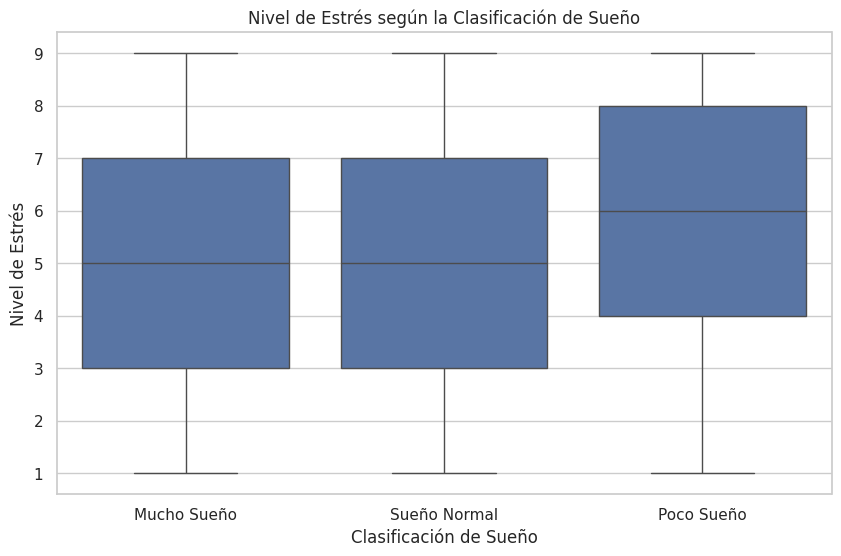

In [60]:
# Analizar cómo varía el nivel de estrés en cada grupo de sueño
sns.set(style="whitegrid")
plt.figure(figsize=(10, 6))
sns.boxplot(x='Clasificacion_Suenio', y='Stress_Level', data=anxiety_high)
plt.title('Nivel de Estrés según la Clasificación de Sueño')
plt.xlabel('Clasificación de Sueño')
plt.ylabel('Nivel de Estrés')
plt.show()

### Preguntas:

1. ¿Qué porcentaje del total presenta niveles altos de ansiedad?
   Para realizar esta prueba, elegí los valores que superar el 80% de ansiedad en total 185/1200 datos del dataset representado el 15.4% del total de los datos
   
2. ¿Existe una relación visible entre las horas de sueño y el nivel de estrés?
   Si, las gráficas muestran que para los niveles altos de ansiedad y las horas de sueño muestran una correlación negativa, es decir, a menos horas de sueño más nivel de estrés.


---
## Paso 6: Ordenamiento

Ahora vas a ordenar el dataset para encontrar a las personas con mayor satisfacción de vida y menor puntaje de soledad. ¿Puedes descubrir algún patrón? ¿Qué tienen en común estas personas?

---

In [67]:
# Ordenar los datos con mayor Satisfacción de Vida(Life_Satisfaction_Score) y menor puntaje de Soledad(Loneliness_Score)
df_mental_health.sort_values(
    by=['Life_Satisfaction_Score', 'Loneliness_Score'],
    ascending=[False, True],
    inplace=True
)
df_mental_health.head(10)

,Age,Gender,Education_Level,Employment_Status,Sleep_Hours,Physical_Activity_Hrs,Social_Support_Score,Anxiety_Score,Depression_Score,Stress_Level,...,Medication_Use,Therapy,Meditation,Substance_Use,Financial_Stress,Work_Stress,Self_Esteem_Score,Life_Satisfaction_Score,Loneliness_Score,Clasificacion_Suenio
14,53,Male,Bachelor's,Employed,4.9,1.5,5,17,4,6,...,Not Reported,0,1,Occasional,8,4,6,9,1,Poco Sueño
33,44,Male,Bachelor's,Employed,7.2,1.7,3,4,4,8,...,Not Reported,0,0,Not Reported,6,6,7,9,1,Mucho Sueño
83,61,Female,PhD,Unemployed,5.7,1.8,4,17,20,9,...,Not Reported,0,1,Not Reported,7,8,6,9,1,Sueño Normal
92,31,Female,PhD,Employed,6.8,0.4,8,20,18,5,...,Not Reported,0,0,Occasional,1,5,4,9,1,Sueño Normal
103,43,Female,Other,Student,5.5,5.1,9,12,6,6,...,Occasional,1,0,Not Reported,6,8,8,9,1,Sueño Normal
217,25,Female,Master's,Employed,6.9,3.4,4,15,5,1,...,Not Reported,0,0,Occasional,3,5,6,9,1,Sueño Normal
262,49,Female,High School,Retired,3.6,0.7,6,14,15,6,...,Not Reported,0,0,Not Reported,3,2,4,9,1,Poco Sueño
391,44,Other,PhD,Retired,7.4,2.4,4,7,7,4,...,Regular,1,0,Occasional,3,4,3,9,1,Mucho Sueño
438,41,Female,Master's,Employed,5.4,0.2,1,18,9,8,...,Not Reported,0,1,Not Reported,2,6,4,9,1,Sueño Normal
675,29,Male,Other,Unemployed,8.0,0.4,3,7,9,8,...,Not Reported,0,0,Not Reported,8,5,5,9,1,Mucho Sueño


### Preguntas:

1. ¿Qué características comunes encuentras en estas 10 personas?
   Estas personas en su mayoría son mujeres, empleados con un horiario de sueño mayor a 3.5 hs, con actividad física, medio alto nivel de ansiedad, medio alto nivel de estrés, la medicación no reportada, en su mayoria no tienen terapia ni meditación, no reportadas las sustancias usadas, medio bajo estrés financiera, medio estrés laboral, medio alta autoestima.

2. ¿Qué hipótesis podrías plantear sobre el vínculo entre satisfacción y soledad?
    Un mayor nivel de soledad se asocia con una menor satisfacción de vida.

---
## Paso 7: Guardado de Resultados

Filtra el dataset para encontrar a las personas que reciben terapia y que además tienen un nivel bajo de estrés (por debajo de la mediana). Una vez que tengas este subconjunto, guarda la información en un nuevo archivo CSV para tenerlo listo para futuros análisis.

---

In [70]:
# Fltrar los datos que reciben terapia (Theraphy=1) y tienen un nivel bajo de estrés (Stress_Level < mediana)
stress_bajo = df_mental_health[
    (df_mental_health['Therapy'] == 1) &
    (df_mental_health['Stress_Level'] < df_mental_health['Stress_Level'].median())
].reset_index(drop=True)
stress_bajo.head(10)

,Age,Gender,Education_Level,Employment_Status,Sleep_Hours,Physical_Activity_Hrs,Social_Support_Score,Anxiety_Score,Depression_Score,Stress_Level,...,Medication_Use,Therapy,Meditation,Substance_Use,Financial_Stress,Work_Stress,Self_Esteem_Score,Life_Satisfaction_Score,Loneliness_Score,Clasificacion_Suenio
0,44,Other,PhD,Retired,7.4,2.4,4,7,7,4,...,Regular,1,0,Occasional,3,4,3,9,1,Mucho Sueño
1,48,Female,High School,Student,7.4,1.3,5,15,12,4,...,Occasional,1,1,Not Reported,9,3,6,9,2,Mucho Sueño
2,21,Male,Other,Employed,7.1,5.0,6,9,9,3,...,Not Reported,1,1,Frequent,1,1,8,9,3,Mucho Sueño
3,61,Non-Binary,Master's,Unemployed,7.1,1.4,7,11,14,2,...,Not Reported,1,0,Not Reported,5,2,1,9,5,Mucho Sueño
4,63,Male,Master's,Employed,8.1,3.0,5,16,15,2,...,Not Reported,1,1,Not Reported,1,8,8,9,6,Mucho Sueño
5,41,Female,Bachelor's,Employed,5.4,0.2,7,4,1,3,...,Not Reported,1,1,Occasional,1,7,3,9,6,Sueño Normal
6,45,Female,PhD,Retired,9.8,1.7,2,3,5,1,...,Regular,1,0,Not Reported,4,5,4,9,7,Mucho Sueño
7,54,Female,Bachelor's,Unemployed,7.1,0.1,5,5,13,3,...,Regular,1,0,Not Reported,8,1,8,9,7,Mucho Sueño
8,43,Male,Other,Employed,5.1,0.9,7,1,9,1,...,Not Reported,1,0,Not Reported,5,2,1,9,8,Sueño Normal
9,50,Female,Master's,Unemployed,6.6,3.0,7,4,3,1,...,Not Reported,1,1,Not Reported,8,1,2,9,9,Sueño Normal


In [69]:
# Exportar los datos de stress_bajo a un archivo CSV
stress_bajo.to_csv(carpeta+'stress_bajo.csv', index=False)

### Preguntas:

1. ¿Cuántas personas cumplen con ambas condiciones?
   108 personas cumplen con estas condiciones
2. ¿Qué conclusiones puedes hacer sobre la relación entre terapia y nivel de estrés en este conjunto?
   En su mayoria son mujeres con terapia y bajo nivel de estrés, alto medio horas de sueño, actividad física, alta satisfacción de vida, es decir, la terapia ayuda a disminuir el estrés, tener una buena satisfacciónb de vida, bajo nivel de soledad, un buen horario de sueño, trabajo sin estrés laboral, alta autoestima.

---
## Paso 8: Visualización Opcional

Para finalizar, crea un gráfico que muestre la media de autoestima (`Self_Esteem_Score`) según el género. Observa si hay diferencias entre géneros y reflexiona sobre los factores que podrían influir en esos resultados.

---

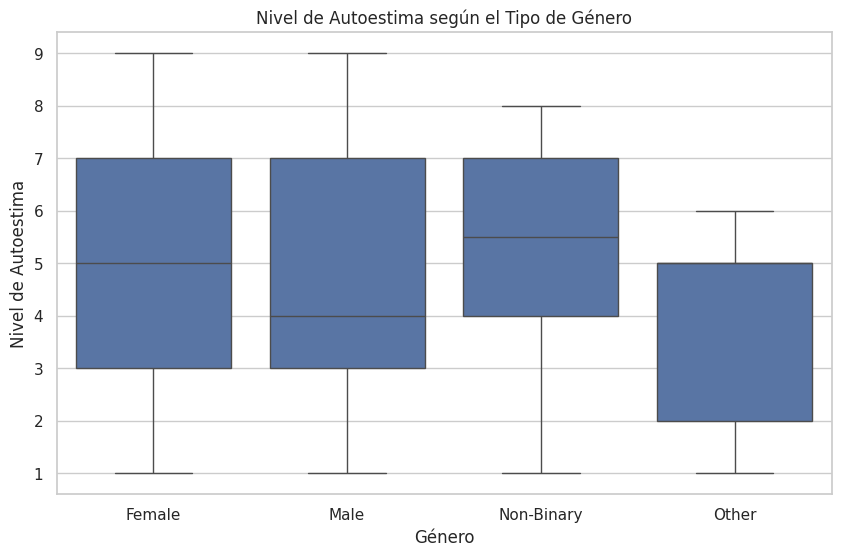

In [71]:
# Visualizar la Autoestima (Self_Esteem_Score) de acuerdo el género(Gender) 
sns.set(style="whitegrid")
plt.figure(figsize=(10, 6))
sns.boxplot(x='Gender', y='Self_Esteem_Score', data=anxiety_high)
plt.title('Nivel de Autoestima según el Tipo de Género')
plt.xlabel('Género')
plt.ylabel('Nivel de Autoestima')
plt.show()




### Preguntas:

1. ¿Hay diferencias notables entre los géneros en cuanto a autoestima?

   Del gráfico anterior se puede observar que la distribución para Masculino y Femenino es similar, la mediana está cerca del centro de la gráfica lo que sugiere una gráfica simétrica. El género No-Binario presenta una mediana más alta que los géneros anteriores, lo que sugire un nivel mayor de autoestima que el promedio, mientras el género que engloba a otros muestruna distribución más baja en comparación al resto, con una mediana más baja y de rango meno lo que menor variabilidad en los datos.

2. ¿Qué factores del dataset podrían explicar estas diferencias?

   Se puede mencionar que los factores con impacto directo podrían ser: el apoyo social está relacionado con una mayor autoestima, niveles altos de ansiedad pueden afectar negativamente la autoestima, así como la depresión y estrés.
    
   Mientras que los aspectos con impacto inderecto podrían ser: la edad, educación, la situaciń laboral.